# MAGIC Telescope & Concrete Strength: Mock Exam (Data & AI 3)

Mock exam for the course **Data & AI 3** (T1), with my answers. The answer key is in `mock-exam-solutions.ipynb`.

**Datasets:**
- `data/magic04.csv`: MAGIC gamma telescope measurements; `class` is `g` (gamma) or `h` (hadron)
- `data/magic04-2.csv`: a description for each class
- `../../05a-ml-basics/data/Concrete_Data.csv`: concrete ingredients and compressive strength (`csMPa`)

**Questions:**
- **Q1–Q7:** pandas, merging, min-max scaling and a boxplot
- **Q8:** a decision tree classifier for `class`, tuned with grid search
- **Q9:** the output of a tiny neural network, worked out by hand
- **Q10:** a neural network that predicts concrete strength

---

# SETUP

### Import libraries

In [ ]:
### basic libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error

### Q8
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import classification_report, accuracy_score
from sklearn.metrics import confusion_matrix

### Q10
from tensorflow.keras import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam

### Auxiliary code

In [ ]:
def plot_loss(history):
    plt.plot(history.history['loss'])
    if 'val_loss' in history.history:
        plt.plot(history.history['val_loss'])
        plt.legend(['Train', 'Val'], loc='upper left')
    plt.title('Model loss')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.show()

### Load data

In [ ]:
magic04 = pd.read_csv('data/magic04.csv', sep=",", decimal=".", header=0)
magic04_2 = pd.read_csv('data/magic04-2.csv', sep=",", decimal=".", header=0)
concrete_data = pd.read_csv('../../05a-ml-basics/data/Concrete_Data.csv', sep=",", decimal=".", header=0)

print(f'loaded magic04: {magic04.shape}')
print(f'loaded magic04_2: {magic04_2.shape}')
print(f'loaded concrete_data: {concrete_data.shape}')

loaded magic04: (19020, 11)
loaded magic04_2: (2, 2)
loaded concrete_data: (1030, 9)


---

# QUESTIONS

Questions 1 to 8 make use of the dataset <strong>data/magic04.csv</strong>. In addition, question 4 makes use of <strong>data/magic04-2.csv</strong>

### Question 1 (1 point)

Create a new field <em>fWidth_Double</em> with as value the value of <em>fWidth</em> multiplied by 2.

Create a new field <em>fWidth_Squared</em> with as value the value of <em>fWidth</em> squared.

<strong>Use 2 different ways to do the calculations for both subquestions: once with Pandas and once with NumPy!</strong>  

In [ ]:
# Solution Q1

df_q1 = magic04[['fWidth']].copy()
df_q1['fWidth_Double_pandas'] = df_q1['fWidth'].multiply(2)  # OR magic04['fWidth'] * 2
df_q1['fWidth_Double_numpy'] = np.array(df_q1['fWidth']) * 2

df_q1['fWidth_Squared_pandas'] = df_q1['fWidth'].pow(2)
df_q1['fWidth_Squared_numpy'] = np.square(np.array(df_q1['fWidth']))

print('it is 5 first rows of df_q1:')
df_q1.head()

it is 5 first rows of df_q1:


,fWidth,fWidth_Double_pandas,fWidth_Double_numpy,fWidth_Squared_pandas,fWidth_Squared_numpy
0,16.0021,32.0042,32.0042,256.067204,256.067204
1,11.7235,23.4470,23.4470,137.440452,137.440452
2,136.0310,272.0620,272.0620,18504.432961,18504.432961
3,9.5728,19.1456,19.1456,91.638500,91.638500
4,30.9205,61.8410,61.8410,956.077320,956.077320


### Question 2 (1 point)

Create a dataframe 'filtered_df' with the rows of df where <em>fConc</em> is greater than 0.4. Print out how many rows dataframe 'filtered_df' has.

In [ ]:
# Solution Q2
# Filter the data
filtered_df = magic04[magic04['fConc'] > 0.4]

print(f"Number of rows in filtered_df: {len(filtered_df)}")
# OR
print(f"Number of rows in filtered_df: {filtered_df.shape[0]}")


Number of rows in filtered_df: 7872
Number of rows in filtered_df: 7872


### Question 3 (2 points)

For each unique value in the column `class`, calculate the median, and standard deviation of fSize

In [ ]:
# Solution Q3
result = magic04.groupby('class').aggregate({'fSize': ['median', 'std']})

print('median and std of fSize for each class:\n')
print(result)

median and std of fSize for each class:

         fSize          
        median       std
class                   
g      2.70480  0.463083
h      2.79765  0.480612


### Question 4 (1 point)

Merge the two datasets so that a description is added to every row. Inspect both to determine which columns to merge on. Save the merged DataFrame to a new variable.

In [ ]:
# Solution Q4
merged_df = pd.merge(magic04, magic04_2, left_on='class', right_on='type', how='inner').drop('type', axis=1)

print(f'the shape of merged_df is:{merged_df.shape}')
print(merged_df.head())

the shape of merged_df is:(19020, 12)
    fLength    fWidth   fSize   fConc  fConc1     fAsym  fM3Long  fM3Trans  \
0   28.7967   16.0021  2.6449  0.3918  0.1982   27.7004  22.0110   -8.2027   
1   31.6036   11.7235  2.5185  0.5303  0.3773   26.2722  23.8238   -9.9574   
2  162.0520  136.0310  4.0612  0.0374  0.0187  116.7410 -64.8580  -45.2160   
3   23.8172    9.5728  2.3385  0.6147  0.3922   27.2107  -6.4633   -7.1513   
4   75.1362   30.9205  3.1611  0.3168  0.1832   -5.5277  28.5525   21.8393   

    fAlpha     fDist class        description  
0  40.0920   81.8828     g  the g type - 1234  
1   6.3609  205.2610     g  the g type - 1234  
2  76.9600  256.7880     g  the g type - 1234  
3  10.4490  116.7370     g  the g type - 1234  
4   4.6480  356.4620     g  the g type - 1234  


### Question 5 (2 points)

Normalize the <em>fLength</em> and <em>fWidth</em> columns to a range between 0 and 1 using min-max scaling. Print out the original <em/>fLength</em> and <em>fWidth</em> columns along with the normalized columns.


In [ ]:
# Solution Q5
scaler_mm = MinMaxScaler()

magic04_copy = magic04[['fLength', 'fWidth']].copy()

scaler_mm = MinMaxScaler()
normalized = scaler_mm.fit_transform(magic04_copy[['fLength', 'fWidth']])

# print(normalized)
magic04_copy['fLength_normalized'] = normalized[:, 0]
magic04_copy['fWidth_normalized'] = normalized[:, 1]

print('original fLength and fWidth with normalized fLength and fWidth columns:')
print(magic04_copy.head())


original fLength and fWidth with normalized fLength and fWidth columns:
    fLength    fWidth  fLength_normalized  fWidth_normalized
0   28.7967   16.0021            0.074306           0.062415
1   31.6036   11.7235            0.082815           0.045727
2  162.0520  136.0310            0.478241           0.530579
3   23.8172    9.5728            0.059212           0.037338
4   75.1362   30.9205            0.214774           0.120603


### Question 6 (1 points)

Using your merged dataset from question 4, make sure the description is updated by only keeping the part before the hyphen (-)

In [ ]:
# Solution Q6
merged_df['description'] = merged_df['description'].str.split('-').str.get(0)

merged_df.head()

,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist,class,description
0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,g,the g type
1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,g,the g type
2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,g,the g type
3,23.8172,9.5728,2.3385,0.6147,0.3922,27.2107,-6.4633,-7.1513,10.4490,116.7370,g,the g type
4,75.1362,30.9205,3.1611,0.3168,0.1832,-5.5277,28.5525,21.8393,4.6480,356.4620,g,the g type


### Question 7 (2 points)

How does the distribution of <em>fWidth</em> vary across different levels of <em>fConc</em>? Plot a boxplot to compare <em>fWidth</em> distribution across several ranges or bins of <em>fConc</em>

In [ ]:
# Solution Q7

# magic04[['fWidth','fConc']].describe()

magic04['fConc_bin'] = pd.cut(
    magic04['fConc'],
    bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0],
    labels=['0–0.2', '0.2–0.4', '0.4–0.6', '0.6–0.8', '0.8–1.0']
)

In [ ]:
# magic04['fConc_bin'] = np.nan
magic04.drop('fConc_bin', axis=1, inplace=True)
for i in range(magic04.shape[0]):
    val = magic04.loc[i, 'fConc']
    result = '0.8-1.0'

    if val < 0.2:
        result = '0-0.2'
    elif 0.2 <= val < 0.4:
        result = '0.2-0.4'
    elif 0.4 <= val < 0.6:
        result = '0.4-0.6'
    elif 0.6 <= val < 0.8:
        result = '0.6-0.8'
    else:
        result = '0.8-1.0'

    magic04.loc[i, 'fConc_bin']  = result

C:\Users\noosh\AppData\Local\Temp\ipykernel_3440\1492295967.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='fConc_bin', y='fWidth', data=magic04, palette='Blues')


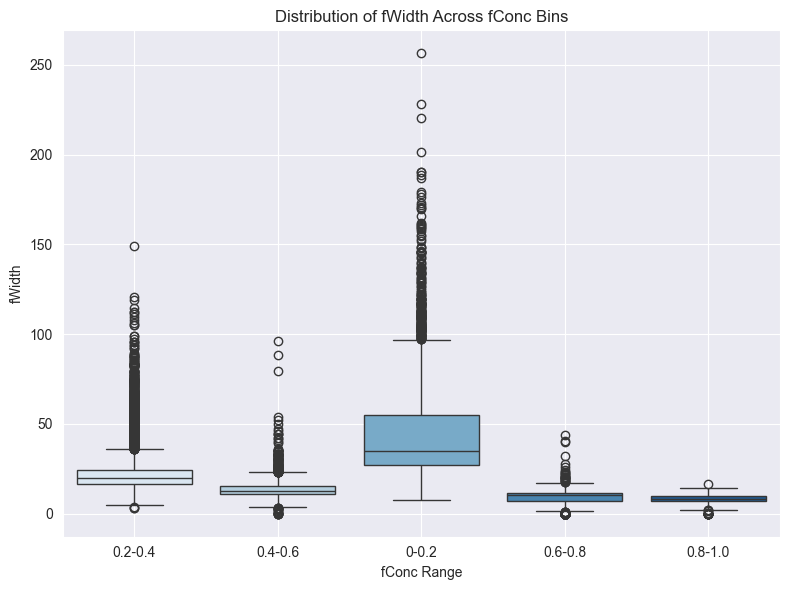

In [ ]:
plt.figure(figsize=(8, 6))
sns.boxplot(x='fConc_bin', y='fWidth', data=magic04, palette='Blues')

plt.xlabel("fConc Range")
plt.ylabel("fWidth")
plt.title("Distribution of fWidth Across fConc Bins")
plt.grid(True)
plt.tight_layout()
plt.show()


### Question 8 (5 points)

Develop a model to predict <em>class</em> using the features <em>fLength, fWidth, fSize</em>. Use a decision tree and split your data into train and test sets (80/20 split). Use random state 42.

Use grid search with cross-validation (with 2 folds) to find the best hyperparameters. Check for following hyperparameters:

- criterion: 'gini', 'entropy'
- max_depth': 3, 5, 10
- min_samples_split: 2, 5, 10
- min_samples_leaf: 1, 2, 4

Evaluate the quality of the best model on the test set (refit if necessary on the proper data) (is this a good model or bad model, would you use this model, explain why).

Check if this model is overfitting or underfitting and explain your answer.

List the hyperparameters you would use and explain why.

Describe what you could do to improve the model and explain why this could improve the model.

In [ ]:
# Solution Q8

# DATA PREPARATION
X_cls = magic04[['fLength', 'fWidth', 'fSize']]
y_cls = magic04['class']

# Split
X_tr, X_tst, y_tr, y_tst = train_test_split(X_cls, y_cls, train_size=0.8, random_state=42)

In [ ]:
# Define model and hyperparameter grid
dt = DecisionTreeClassifier(random_state=42)  # class_weight='balanced'

param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 5, 10],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_search = GridSearchCV(dt, param_grid, cv=2, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_tr, y_tr)

# Evaluation
print("Best Parameters:", grid_search.best_params_)  # Best model from grid search
print('Mean cross validated score for best estimator:', np.round(grid_search.best_score_, 3))


Best Parameters: {'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5}
Mean cross validated score for best estimator: 0.789


Train Accuracy: 0.8202549947423764

Classification Report:
               precision    recall  f1-score   support

           g       0.81      0.95      0.87      9872
           h       0.86      0.58      0.70      5344

    accuracy                           0.82     15216
   macro avg       0.83      0.77      0.78     15216
weighted avg       0.83      0.82      0.81     15216



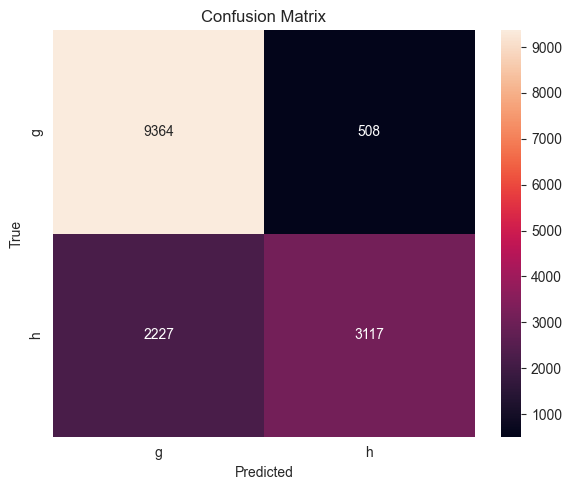

In [ ]:
best_model = grid_search.best_estimator_

# Predict on the train set
y_trian_pred = best_model.predict(X_tr)
print("Train Accuracy:", accuracy_score(y_tr, y_trian_pred))
print("\nClassification Report:\n", classification_report(y_tr, y_trian_pred))

cm = confusion_matrix(y_tr, y_trian_pred)
labels = np.unique(np.concatenate([y_tr, y_trian_pred]))  # All labels for clearer interpretation
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='', xticklabels=labels, yticklabels=labels)  # fmt='' shows the values in full
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

Test Accuracy: 0.7907465825446898

Classification Report:
               precision    recall  f1-score   support

           g       0.78      0.93      0.85      2460
           h       0.81      0.53      0.64      1344

    accuracy                           0.79      3804
   macro avg       0.80      0.73      0.75      3804
weighted avg       0.79      0.79      0.78      3804



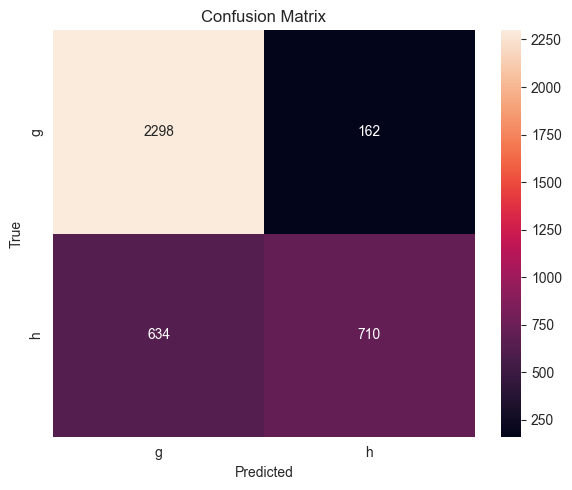

In [ ]:
# Predict on the test set
y_tst_pred = best_model.predict(X_tst)
print("Test Accuracy:", accuracy_score(y_tst, y_tst_pred))
print("\nClassification Report:\n", classification_report(y_tst, y_tst_pred))

cm = confusion_matrix(y_tst, y_tst_pred)
labels = np.unique(np.concatenate([y_tst, y_tst_pred]))  # All labels for clearer interpretation
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='', xticklabels=labels, yticklabels=labels)  # fmt='' shows the values in full
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

### Question 9 (1 point)

A very small neural network has an input layer with 2 nodes and an output layer with 1 node. There are no hidden nodes. Calculate the feedforward pass if the input is [1, 0.5, 1] the weights are [0.3, 0.5, -0.1] and the bias is -0.7. The activation function used by the output layer is sigmoid. Do not use Tensorflow/Keras, but calculate the result yourself using Numpy arrays and the Python Math module.

In [ ]:
input = np.array([1, 0.5, 1])
weights = np.array([0.3, 0.5, -0.1])
bias = -0.7

integration = np.sum(input * weights) + bias

# Biggest influence: 1st

# activation = sigmoid
activation = 1 / (1 + math.exp(-integration))

print('integration:', np.round(integration, 3))
print('activation (sigmoid):', np.round(activation, 3))
# The first input (weight 0.3) has larger absolute influence than the second (-0.1).

integration: -0.25
activation (sigmoid): 0.438


### Question 10 (5 points)

This question makes use of dataset <strong>../../05a-ml-basics/data/Concrete_Data.csv</strong>

Develop a model to predict <em>csMPa</em> based on a neural network using <em>cement</em>, <em>slag</em>, <em>coarseaggregate</em>, <em>age</em> and <em>fineaggregate</em> as predictors.

Do some parameter tuning (for at least two parameters).

Evaluate the quality of the model (is this a good model or bad model, would you use this model, explain why).

Describe what you could do to improve the model and explain why this could improve the model.

In [ ]:
df = concrete_data

y = df['csMPa']
X = df[['cement', 'slag', 'coarseaggregate', 'age', 'fineaggregate']]

correlation = df[['csMPa', 'cement', 'slag', 'coarseaggregate', 'age', 'fineaggregate']].corr(numeric_only=True)
print(correlation['csMPa'])

csMPa              1.000000
cement             0.497832
slag               0.134829
coarseaggregate   -0.164935
age                0.328873
fineaggregate     -0.167241
Name: csMPa, dtype: float64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42)

# Scale features (fit on train only)
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

n_features = X.shape[1]
n_features

5

In [ ]:
# input
inputs = Input(shape=(n_features,))
# 2 hidden layer
x = Dense(32, activation='relu')(inputs)
x = Dense(16, activation='relu')(x)
# output layer
outputs = Dense(1, activation='linear')(x)
# construct the model
model = Model(inputs, outputs, name='DATA3')
# compile the model
model.compile(optimizer=Adam(learning_rate=1e-3),
              loss='mean_squared_error',
              metrics=['mean_absolute_percentage_error'])
# print a summary
model.summary()

Model: "DATA3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 5)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 737 (2.88 KB)

 Trainable params: 737 (2.88 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 1539.4227 - mean_absolute_percentage_error: 98.5612 - val_loss: 1540.6333 - val_mean_absolute_percentage_error: 97.8070
Epoch 2/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1494.0676 - mean_absolute_percentage_error: 96.2743 - val_loss: 1480.2358 - val_mean_absolute_percentage_error: 95.1133
Epoch 3/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1419.8676 - mean_absolute_percentage_error: 92.3571 - val_loss: 1382.8752 - val_mean_absolute_percentage_error: 90.5630
Epoch 4/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1304.1290 - mean_absolute_percentage_error: 86.1217 - val_loss: 1236.7872 - val_mean_absolute_percentage_error: 83.3229
Epoch 5/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1137.8439 - mean_absolute_percentage_error: 77.0222 - val_loss: 1036.3748 - val_mean_absolute_percentage_error: 72.4981
Epoch 6/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 923.3352 - mean_absolute_percentage_error: 65.3770 -

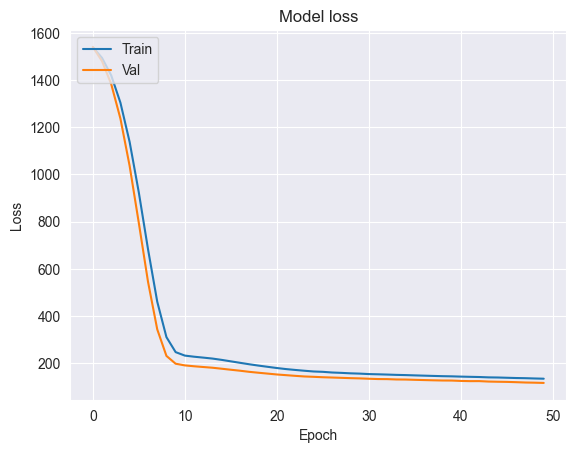

In [ ]:
# train the model
history = model.fit(
    X_train_scaled,  # Train features
    y_train,  # Train target (the house
    epochs=50,
    batch_size=32,
    validation_split=0.1,
)
# plot loss function
plot_loss(history)


In [ ]:
# Evaluate the model
eval_train = model.evaluate(X_train_scaled, y_train)
print('test MSE, MAPE:', eval_train)

y_trian_pred = model.predict(X_train_scaled)
r2 = r2_score(y_train, y_trian_pred)
print("R²:", r2)


26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 131.9185 - mean_absolute_percentage_error: 37.0456 
test MSE, MAPE: [131.91848754882812, 37.045589447021484]
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
R²: 0.5356395660057681


In [ ]:
# Evaluate the model
eval_test = model.evaluate(X_test_scaled, y_test)
print('test MSE, MAPE:', eval_test)

y_test_pred = model.predict(X_test_scaled)
r2 = r2_score(y_test, y_test_pred)
print("R²:", r2)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 142.6348 - mean_absolute_percentage_error: 39.3190 
test MSE, MAPE: [142.6348419189453, 39.3189697265625]
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
R²: 0.44645856769142567


3. Hyperparameter Optimization
- Use KerasTuner or GridSearchCV to find optimal learning rate, layer size, etc.
4. Cross-Validation
- Use KFold to ensure generalization and reduce variance in evaluation.


# END OF EXAM

---